# PaySim · Motif Finding
## Khánh — cycle 3-node và TRANSFER → CASH_OUT

**Dataset xuyên suốt:** PaySim, full graph **9.073.900 tài khoản / 6.362.620 giao dịch**.
Đỉnh là tài khoản, cạnh là giao dịch có hướng từ người gửi đến người nhận.

| Thành phần | Dữ liệu / ý nghĩa |
|---|---|
| Input | `data/processed/paysim/vertices.parquet`, `edges.parquet` |
| `type` | TRANSFER, CASH_OUT và các loại giao dịch mô phỏng khác |
| `step` | Giờ mô phỏng; không phải timestamp chính xác của từng giao dịch |
| `amount` | Số tiền theo đơn vị mô phỏng của PaySim; không tự gọi là USD |
| `isFraud` | Nhãn đối chiếu, không dùng để lọc relay |
| Output trong notebook | Cycle count, bảng relay, kiểm tra biên và hình minh họa |

### Lộ trình trình bày

**Môi trường → toy cycle → rule relay → chạy full → giải thích kết quả → phụ lục review PageRank → kiểm chứng source.**

Toy và ví dụ PageRank là đồ thị nhỏ tự tạo để giải thích thuật toán, không phải các dataset thực nghiệm bổ sung. Phần review lý thuyết 3.3 được đặt ở phụ lục để mạch trình bày motif không bị gián đoạn.

### Các đầu việc của Khánh được giữ trong notebook

| Hạn | Nội dung |
|---|---|
| 21/9 | Học graph.find và toy cycle 3-node |
| 25/9 | Review 3.3 PageRank: toán, sink-node và ký hiệu |
| 28/9 | Final 3.3 |
| 30/9 | Draft Task 3 PaySim: cycle và relay >10.000 |
| 3/10 | Fix Task 3 PaySim theo tiêu chí review |

**Chạy:** chọn Windows `.venv\Scripts\python.exe` → **Restart Kernel → Run All**.
Notebook tự khởi tạo Spark `local[4]`, heap **6 GiB**. Không cần chạy notebook khác.
Các hình/bảng được nhúng vào file này; không xuất CSV/PNG/log vào repository. Runtime tạm nằm ngoài repo.
PASS tự động không thay phê duyệt của người review.

## 0 · Kiểm tra môi trường và input PaySim


In [1]:
from __future__ import annotations
import ast
import csv
import hashlib
import importlib.metadata as metadata
import json
import math
import os
import platform
import subprocess
import sys
import tempfile
import time
from datetime import datetime, timezone
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch
from IPython.display import display
from graphframes import GraphFrame
from pyspark.sql import DataFrame, SparkSession, functions as F

REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
                 if (p / 'requirements.txt').is_file() and (p / 'src').is_dir())
NOTEBOOK_PATH = REPO_ROOT / 'notebooks/03_khanh_PaySIM_motif.ipynb'
assert os.name == 'nt', 'Chọn Windows .venv; không chạy bằng WSL.'
assert sys.version_info[:2] == (3, 12), 'Cần Python 3.12.'
assert os.path.samefile(sys.executable, REPO_ROOT / '.venv/Scripts/python.exe'), 'Chọn .venv của repo.'
sys.path.insert(0, str(REPO_ROOT))
os.environ['PYTHONUTF8'] = '1'
os.environ['PYTHONIOENCODING'] = 'utf-8'
from src.common.spark_session import get_graph_session

for package, expected in [('pyspark','3.5.1'), ('graphframes-py','0.12.2')]:
    assert metadata.version(package) == expected, (package, metadata.version(package))
dependencies = subprocess.run([sys.executable, '-m', 'pip', 'check'], capture_output=True, text=True)
assert dependencies.returncode == 0, dependencies.stdout + dependencies.stderr
print(dependencies.stdout.strip())
required_inputs = ['data/processed/paysim/vertices.parquet', 'data/processed/paysim/edges.parquet', 'results/paysim/relay_candidates.csv']
for relative in required_inputs:
    assert (REPO_ROOT / relative).exists(), f'Thiếu dữ liệu: {relative}'
started_at = datetime.now(timezone.utc)
started_clock = time.perf_counter()
checks_passed = {}
plt.rcParams.update({'figure.dpi':110, 'font.family':'DejaVu Sans', 'font.size':10,
                     'axes.spines.top':False, 'axes.spines.right':False})
print('Windows:', platform.platform())
print('Python:', sys.version.split()[0], '|', sys.executable)
print('Bắt đầu UTC:', started_at.isoformat())


No broken requirements found.
Windows: Windows-11-10.0.26300-SP0
Python: 3.12.10 | D:\desktop_informations\sgk năm 4\sgk kì 1 năm 4\bigdata - phong\project_graphx\graphguard-amls-detection\.venv\Scripts\python.exe
Bắt đầu UTC: 2026-10-18T13:43:03.702160+00:00


Đầu vào đã được Task 1 xây thành Parquet. Các cell sau chỉ đọc full graph và chạy phần motif của Khánh. Trước khi tạo Spark, kiểm tra Windows Python 3.12, dependency và kernel của repo; sau khi tạo Spark, kiểm tra Java 17 thực sự được JVM sử dụng.


In [2]:
# Vẽ ngay trong notebook: nhãn cạnh đặt lệch khỏi mũi tên để dễ đọc.
def draw_graph(nodes, edges, title, positions=None, colors=None):
    if positions is None:
        angles = np.linspace(np.pi / 2, np.pi / 2 - 2 * np.pi, len(nodes), endpoint=False)
        positions = {node: (np.cos(angle), np.sin(angle)) for node, angle in zip(nodes, angles)}
    colors = colors or ['#2563eb'] * len(edges)
    fig, ax = plt.subplots(figsize=(10, 5))
    for index, (source, target, label) in enumerate(edges):
        start, end = np.array(positions[source]), np.array(positions[target])
        direction = end - start
        normal = np.array([-direction[1], direction[0]]) / np.linalg.norm(direction)
        label_position = (start + end) / 2 + 0.22 * normal
        source_padding = 55 if max(map(len, nodes[source].splitlines())) > 10 else 35
        target_padding = 55 if max(map(len, nodes[target].splitlines())) > 10 else 35
        ax.add_patch(FancyArrowPatch(
            start, end, arrowstyle='-|>', mutation_scale=19, linewidth=2,
            shrinkA=source_padding, shrinkB=target_padding,
            color=colors[index % len(colors)], connectionstyle='arc3,rad=0.04',
        ))
        ax.text(
            *label_position, label, ha='center', va='center', fontsize=9,
            bbox={'facecolor': 'white', 'edgecolor': 'none', 'alpha': 0.95},
        )
    for node, label in nodes.items():
        ax.text(
            *positions[node], label, ha='center', va='center', color='#0f172a',
            bbox={'boxstyle': 'round,pad=0.7', 'facecolor': '#eff6ff', 'edgecolor': '#93c5fd'},
        )
    ax.set(xlim=(-1.6, 1.6), ylim=(-1.4, 1.5), title=title)
    ax.axis('off')
    plt.show()

runtime_temp = tempfile.TemporaryDirectory(prefix='graphguard-paysim-',ignore_cleanup_errors=True)
spark = get_graph_session('GraphGuard-Khanh-PaySim',driver_memory='6g',shuffle_partitions=8,
    extra_configs={'spark.master':'local[4]','spark.default.parallelism':'4',
                   'spark.ui.enabled':'false','spark.ui.showConsoleProgress':'false',
                   'spark.sql.warehouse.dir':(Path(runtime_temp.name)/'warehouse').as_uri()})
spark.sparkContext.setLogLevel('ERROR')
java_version = spark.sparkContext._jvm.java.lang.System.getProperty('java.version')
assert java_version.startswith('17.'), java_version
runtime = {'system':platform.system(),'python':platform.python_version(),'spark':spark.version,
    'graphframes':metadata.version('graphframes-py'),'java':java_version,
    'master':spark.sparkContext.master,'driver_memory':spark.sparkContext.getConf().get('spark.driver.memory'),
    'session_timezone':spark.conf.get('spark.sql.session.timeZone')}
runtime['dataset'] = 'PaySim'
display(pd.DataFrame([runtime]))
checks_passed['Windows Python 3.12 / JDK 17 / dependencies'] = True


,system,python,spark,graphframes,java,master,driver_memory,session_timezone,dataset
0,Windows,3.12.10,3.5.1,0.12.2,17.0.20.1,local[4],6g,Asia/Saigon,PaySim


In [3]:
# Đọc đủ vertices/edges Parquet rồi tạo GraphFrame.
# Production: src/common/graph_utils.py

def load_graph(spark: SparkSession, data_dir: str) -> GraphFrame:
    """Load GraphFrame từ thư mục chứa vertices.parquet và edges.parquet."""
    data_path = Path(data_dir)
    vertices_path = data_path / "vertices.parquet"
    edges_path = data_path / "edges.parquet"

    if not vertices_path.exists():
        raise FileNotFoundError(f"Không tìm thấy vertices tại: {vertices_path}")
    if not edges_path.exists():
        raise FileNotFoundError(f"Không tìm thấy edges tại: {edges_path}")

    v_df = spark.read.parquet(str(vertices_path))
    e_df = spark.read.parquet(str(edges_path))
    return GraphFrame(v_df, e_df)


## 1 · Hiểu query cycle bằng toy graph

Query gán tên cho **đỉnh và cạnh**, tìm mọi cách gán khớp cấu trúc. Ba ID khác nhau loại self-loop và đường đóng chỉ đi qua hai tài khoản. A→B→C→A có ba điểm bắt đầu nên sinh ba dòng. Giữ `a` nhỏ nhất khử phép xoay, giữ nguyên chiều cạnh.


In [4]:
MOTIF_PATTERN = "(a)-[e1]->(b);(b)-[e2]->(c);(c)-[e3]->(a)"


In [5]:
# Đầy đủ toy graph, truy vấn và kiểm chứng số phép xoay.
# Production: src/motif/toy_cycle.py

def build_toy_graph(spark: SparkSession) -> GraphFrame:
    """Tạo A → B → C → A, mỗi đỉnh và cạnh có thuộc tính để quan sát."""
    vertices = spark.sql(
        "SELECT * FROM VALUES "
        "('A', 'Alice'), ('B', 'Bob'), ('C', 'Carol') "
        "AS v(id, name)"
    )
    edges = spark.sql(
        "SELECT * FROM VALUES "
        "('A', 'B', 'transfer'), ('B', 'C', 'transfer'), "
        "('C', 'A', 'transfer') "
        "AS e(src, dst, kind)"
    )
    return GraphFrame(vertices, edges)

def find_three_node_cycles(graph: GraphFrame) -> DataFrame:
    """Chạy đúng motif đã giao và loại các đường đóng có đỉnh trùng nhau."""
    return (
        graph.find(MOTIF_PATTERN)
        .where(
            (F.col("a.id") != F.col("b.id"))
            & (F.col("b.id") != F.col("c.id"))
            & (F.col("c.id") != F.col("a.id"))
        )
    )

def cycle_ids(motifs: DataFrame) -> DataFrame:
    """Lấy ID đỉnh theo thứ tự chiều cạnh; mỗi dòng là một phép xoay."""
    return motifs.select(
        F.col("a.id").alias("a"),
        F.col("b.id").alias("b"),
        F.col("c.id").alias("c"),
    )

def run_demo(spark: SparkSession) -> dict:
    """Trả dữ liệu demo và kiểm tra số kết quả mong đợi trên toy graph."""
    graph = build_toy_graph(spark)
    matches = cycle_ids(find_three_node_cycles(graph))
    rows = sorted(tuple(row) for row in matches.collect())
    expected = [("A", "B", "C"), ("B", "C", "A"), ("C", "A", "B")]
    if rows != expected:
        raise AssertionError(f"Motif sai: mong đợi {expected}, nhận {rows}")

    # Chỉ giữ phép xoay bắt đầu ở ID nhỏ nhất, tránh đếm 1 chu trình 3 lần.
    unique = sorted(row for row in rows if row[0] == min(row))
    if unique != [("A", "B", "C")]:
        raise AssertionError(f"Chu trình duy nhất sai: {unique}")

    return {
        "status": "PASS",
        "pattern": MOTIF_PATTERN,
        "vertices": ["A", "B", "C"],
        "edges": [["A", "B"], ["B", "C"], ["C", "A"]],
        "raw_match_count": len(rows),
        "raw_matches": [list(row) for row in rows],
        "unique_cycle_count": len(unique),
        "unique_cycles": [list(row) for row in unique],
    }


,id,name
0,A,Alice
1,B,Bob
2,C,Carol


,src,dst,kind
0,A,B,transfer
1,B,C,transfer
2,C,A,transfer


,a,b,c
0,A,B,C
1,B,C,A
2,C,A,B


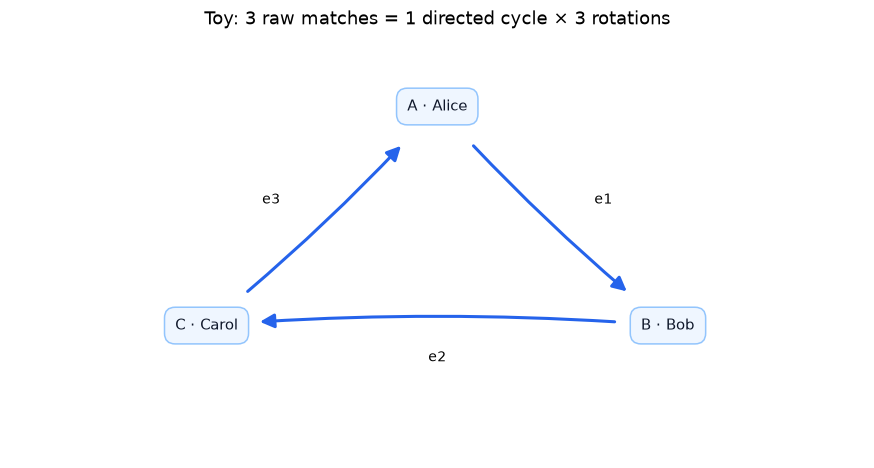

In [6]:
toy = build_toy_graph(spark)
display(toy.vertices.orderBy('id').toPandas())
display(toy.edges.orderBy('src').toPandas())
toy_result = run_demo(spark)
display(pd.DataFrame(toy_result['raw_matches'],columns=['a','b','c']))
assert (toy_result['raw_match_count'],toy_result['unique_cycle_count']) == (3,1)
draw_graph({'A':'A · Alice','B':'B · Bob','C':'C · Carol'},
    [('A','B','e1'),('B','C','e2'),('C','A','e3')],'Toy: 3 raw matches = 1 directed cycle × 3 rotations')
checks_passed['Toy graph.find: 3 rotations / 1 cycle'] = True


## 2 · Định nghĩa motif PaySim: cycle và relay

**Rule:** A −TRANSFER→ B −CASH_OUT→ C, ba tài khoản khác nhau, **cả hai amount >10.000**, `transfer_step <= cashout_step`, khoảng cách tối đa 24 giờ mô phỏng. Không dùng nhãn fraud để chọn ứng viên.

PaySim chỉ ghi giờ; cặp cùng giờ không xác định thứ tự thật. `strict_time=True` loại các cặp này. 24 giờ là tham số phân tích do nhóm chọn. Relay là **cặp giao dịch ứng viên**, chưa chứng minh cùng một khoản tiền đi qua hai hop.


In [7]:
RELAY_PATTERN = "(a)-[e1]->(b);(b)-[e2]->(c)"


In [8]:
# Code production đầy đủ: lọc cạnh, query, amount/time và flatten.
# Production: src/paysim/motif_finding.py

def find_relays(
    graph: GraphFrame, minimum_amount: float, max_gap_hours: int,
    strict_time: bool = False,
) -> DataFrame:
    """Find three-account relays; same-hour order is unknown in PaySim."""
    if not math.isfinite(minimum_amount) or minimum_amount < 0 or max_gap_hours <= 0:
        raise ValueError("finite minimum_amount >= 0 and max_gap_hours > 0 required")
    eligible_edges = graph.edges.where(
        F.col("type").isin("TRANSFER", "CASH_OUT")
        & (F.col("amount") > minimum_amount)
    )
    eligible_graph = GraphFrame(graph.vertices, eligible_edges)
    time_order = (F.col("e1.step") < F.col("e2.step")) if strict_time else (
        F.col("e1.step") <= F.col("e2.step")
    )
    return eligible_graph.find(RELAY_PATTERN).where(
        (F.col("e1.type") == "TRANSFER")
        & (F.col("e2.type") == "CASH_OUT")
        & (F.col("a.id") != F.col("b.id"))
        & (F.col("b.id") != F.col("c.id"))
        & (F.col("a.id") != F.col("c.id"))
        & time_order
        & ((F.col("e2.step") - F.col("e1.step")) <= max_gap_hours)
    )

def relay_rows(matches: DataFrame) -> DataFrame:
    """Flat columns for a CSV of transaction-pair candidates."""
    return matches.select(
        F.col("a.id").alias("source_account"),
        F.col("b.id").alias("middle_account"),
        F.col("c.id").alias("cashout_account"),
        F.col("e1.step").alias("transfer_step"),
        F.col("e2.step").alias("cashout_step"),
        F.col("e1.amount").alias("transfer_amount"),
        F.col("e2.amount").alias("cashout_amount"),
        F.col("e1.isFraud").alias("transfer_isFraud"),
        F.col("e2.isFraud").alias("cashout_isFraud"),
    )


### Kiểm tra rule trước khi chạy full

Các trường hợp cần phân biệt: số tiền **đúng 10.000** bị loại; thời gian ngược bị loại; cặp cùng giờ được giữ ở chế độ mặc định nhưng bị loại khi `strict_time=True`; khoảng cách **đúng 24 giờ** được giữ; ba tài khoản phải khác nhau. Nhãn fraud không quyết định việc relay có được chọn hay không.

Đồ thị hai tài khoản bên dưới còn kiểm chứng self-loop và cycle hai đỉnh không bị nhận nhầm thành cycle ba đỉnh.


In [9]:
# Cùng cấu trúc biên dùng trong test motif của repo; chỉ dùng rule PaySim.
vertices = spark.sql("SELECT * FROM VALUES ('A'),('B'),('D'),('E'),('F'),('X') AS v(id)")
edges = spark.sql(
    "SELECT * FROM VALUES "
    "('A','B','TRANSFER',10000.0,10,0),('X','B','TRANSFER',11000.0,10,1),"
    "('B','A','CASH_OUT',10000.0,12,0),('B','D','CASH_OUT',11000.0,10,0),"
    "('B','E','CASH_OUT',11000.0,34,0),('B','F','CASH_OUT',11000.0,35,0),"
    "('B','A','CASH_OUT',11000.0,9,0),('B','X','CASH_OUT',11000.0,12,0) "
    "AS e(src,dst,type,amount,step,isFraud)"
)
boundary_graph = GraphFrame(vertices, edges)
default_matches = find_relays(boundary_graph, 10_000, 24)
assert sorted(row.id for row in default_matches.select('c.id').collect()) == ['D', 'E']
assert find_relays(boundary_graph, 10_000, 24, strict_time=True).count() == 1

two_vertices = spark.sql("SELECT * FROM VALUES ('A'),('B') AS v(id)")
two_edges = spark.sql("SELECT * FROM VALUES ('A','B'),('B','A'),('A','A') AS e(src,dst)")
assert find_three_node_cycles(GraphFrame(two_vertices, two_edges)).count() == 0
for invalid in (float('nan'), float('inf'), -1.0):
    try:
        find_relays(boundary_graph, invalid, 24)
    except ValueError:
        continue
    raise AssertionError(f'Invalid threshold accepted: {invalid}')
print('PASS: amount, time order, 24-hour boundary, distinct accounts and invalid thresholds.')
checks_passed['PaySim: adversarial relay rules and three-node cycle definition'] = True


PASS: amount, time order, 24-hour boundary, distinct accounts and invalid thresholds.


## 3 · Chạy motif trên full PaySim

Không kết luận cycle full bằng 0 chỉ từ sample. Cell này tìm trên **9.073.900 đỉnh / 6.362.620 cạnh**, sau đó so từng dòng relay với CSV đã commit.


In [10]:
pay_loaded = load_graph(spark,str(REPO_ROOT/'data/processed/paysim'))
pay = GraphFrame(pay_loaded.vertices.select('id').cache(),pay_loaded.edges.select(
    'src','dst','type','amount','step','isFraud').cache())
pay_v,pay_e = pay.vertices.count(),pay.edges.count()
assert (pay_v,pay_e) == (9_073_900,6_362_620)
pay_cycles = find_three_node_cycles(pay)
pay_cycle_count = pay_cycles.count()
pay_directed_count = pay_cycles.where((F.col('a.id')<F.col('b.id')) &
    (F.col('a.id')<F.col('c.id'))).select('a.id','b.id','c.id').distinct().count()
pay_matches = find_relays(pay,10_000.0,24).cache()
pay_relay_count = pay_matches.count()
pay_same_hour = pay_matches.where(F.col('e1.step')==F.col('e2.step')).count()
pay_relays = relay_rows(pay_matches).orderBy('transfer_step','cashout_step','source_account',
    'middle_account','cashout_account','transfer_amount','cashout_amount').toPandas()
pay_metrics = {'scope':'full','vertices':pay_v,'edges':pay_e,'raw_cycles':pay_cycle_count,
    'directed_cycles':pay_directed_count,'relay_pairs':pay_relay_count,'same_hour':pay_same_hour,
    'strict_later':pay_relay_count-pay_same_hour}
assert (pay_cycle_count,pay_directed_count,pay_relay_count,pay_same_hour) == (0,0,30,2)
baseline = pd.read_csv(REPO_ROOT/'results/paysim/relay_candidates.csv')
keys = list(pay_relays.columns)
pd.testing.assert_frame_equal(pay_relays.sort_values(keys).reset_index(drop=True),
    baseline[keys].sort_values(keys).reset_index(drop=True),check_dtype=False,check_exact=True)
display(pd.DataFrame([pay_metrics]))
display(pay_relays.head(10))
assert (pay_relays[['transfer_isFraud','cashout_isFraud']]==0).all().all()
print('PASS: CSV khớp đủ 30/30; hai cạnh của mọi ứng viên đều có nhãn 0.')
checks_passed['Task 3 PaySim full + exact delivered CSV'] = True


,scope,vertices,edges,raw_cycles,directed_cycles,relay_pairs,same_hour,strict_later
0,full,9073900,6362620,0,0,30,2,28


,source_account,middle_account,cashout_account,transfer_step,cashout_step,transfer_amount,cashout_amount,transfer_isFraud,cashout_isFraud
0,C1933517957,C1939958280,C232785081,24,37,265406.49,400729.53,0,0
1,C831358900,C874023329,C1468339976,34,47,1326914.02,292696.43,0,0
2,C1554009922,C874023329,C1468339976,36,47,149467.61,292696.43,0,0
3,C1739712760,C1360393616,C654237876,44,44,161654.47,75989.57,0,0
4,C1483406592,C2013691076,C1228316980,129,132,255345.27,433722.00,0,0
5,C11465170,C1883483535,C792212230,139,139,456477.88,247241.29,0,0
6,C1076477679,C991247178,C1344561835,143,162,195823.90,60387.69,0,0
7,C532453433,C1708070258,C11164223,155,177,1310843.36,406454.19,0,0
8,C1558625741,C1838628808,C224572740,156,158,213684.91,123530.04,0,0
9,C1766969454,C1708070258,C11164223,156,177,822049.92,406454.19,0,0


PASS: CSV khớp đủ 30/30; hai cạnh của mọi ứng viên đều có nhãn 0.


## 4 · Đọc kết quả PaySim qua đồ thị

Hình thứ nhất chọn một relay có giờ CASH_OUT lớn hơn giờ TRANSFER. Mũi tên ghi loại giao dịch, số tiền và giờ mô phỏng. Hai số tiền không cần bằng nhau; dữ liệu chưa chứng minh đây là cùng một khoản tiền.

Hình thứ hai tách 28 cặp có thứ tự giờ rõ với 2 cặp cùng giờ. Cả 30 ứng viên có nhãn đối chiếu bằng 0, nên không được báo cáo thành “30 vụ gian lận”.


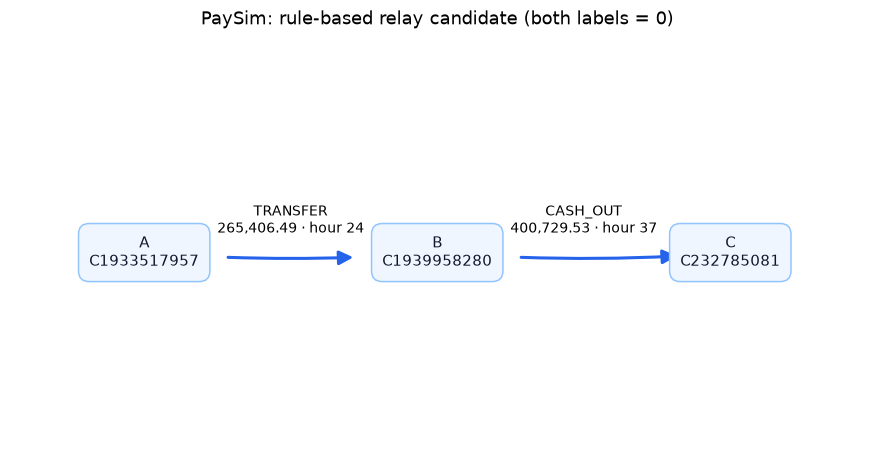

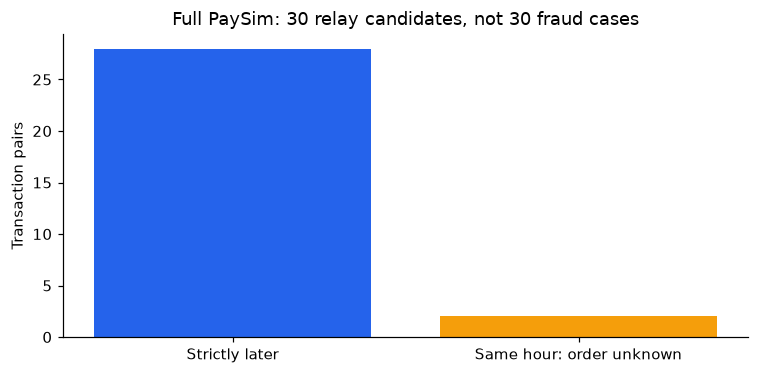

In [11]:
# Chọn ứng viên có thứ tự giờ rõ ràng. Hai amount không cần bằng nhau.
example = pay_relays.loc[pay_relays.cashout_step>pay_relays.transfer_step].iloc[0]
draw_graph({'A':'A\n'+example.source_account,'B':'B\n'+example.middle_account,
            'C':'C\n'+example.cashout_account},
    [('A','B',f'TRANSFER\n{example.transfer_amount:,.2f} · hour {example.transfer_step}'),
     ('B','C',f'CASH_OUT\n{example.cashout_amount:,.2f} · hour {example.cashout_step}')],
    'PaySim: rule-based relay candidate (both labels = 0)',
    positions={'A':(-1.1,0),'B':(0,0),'C':(1.1,0)})
fig,ax = plt.subplots(figsize=(7,3.5))
ax.bar(['Strictly later','Same hour: order unknown'],[pay_relay_count-pay_same_hour,pay_same_hour],
       color=['#2563eb','#f59e0b'])
ax.set(ylabel='Transaction pairs',title='Full PaySim: 30 relay candidates, not 30 fraud cases')
plt.tight_layout()
plt.show()
pay_matches.unpersist()
pay.vertices.unpersist()
pay.edges.unpersist()
spark.catalog.clearCache()


### Kết luận thực nghiệm PaySim

- Query cycle **ba đỉnh** trên full graph cho **0 kết quả**; điều này không tự chứng minh graph không có mọi loại cycle khác.
- Rule TRANSFER → CASH_OUT cho **30 cặp giao dịch**, gồm **28** cặp khác giờ và **2** cặp cùng giờ.
- Toàn bộ relay khớp từng dòng với CSV bàn giao, không chỉ khớp số lượng.
- Không dùng fraud label để lọc ứng viên; nhãn chỉ phục vụ đối chiếu sau query.
- Cửa sổ 24 giờ là tham số phân tích; relay không chứng minh cùng một khoản tiền đi qua hai hop.


## 5 · Phụ lục: review và final PageRank 3.3

### Dẫn xuất qua sáu bước

$A_{vu}$ đếm **số cạnh** từ $v$ tới $u$, $d_{out}(v)=\sum_u A_{vu}$, $N=|V|$, $D$ là tập dangling node. Dùng vector cột, tổng mỗi cột ma trận chuyển bằng 1.

1. **Random walk:** chọn đều một cạnh ra, $\Pr[v\to u]=A_{vu}/d_{out}(v)$.
2. **Transition matrix:** $M_{uv}=A_{vu}/d_{out}(v)$ nếu $d_{out}(v)>0$, ngược lại bằng 0. $r^{(t+1)}=Mr^{(t)}$ là power iteration.
3. **Stationary distribution:** với ma trận stochastic $P$, $r=Pr$, $r\ge0$, $\|r\|_1=1$. Tồn tại chưa đồng nghĩa duy nhất/hội tụ.
4. **Dangling repair:** cột 0 làm mất xác suất (leakage). Với $a_v=1$ khi $v\in D$, đặt $S=M+\frac1N\mathbf e\mathbf a^T$.
5. **Teleportation:** $G=dS+\frac{1-d}{N}\mathbf e\mathbf e^T$, $d=0.85$. $G$ dương và stochastic, có phân phối dừng duy nhất, power iteration hội tụ từ mọi vector xác suất.
6. **Công thức từng đỉnh:**

$$r^{(t+1)}(u)=\frac{1-d}{N}+d\left[\sum_{v:d_{out}(v)>0}\frac{A_{vu}r^{(t)}(v)}{d_{out}(v)}+\frac1N\sum_{v\in D}r^{(t)}(v)\right].$$

### Các điểm review toán, sink và ký hiệu

- Dangling node có out-degree=0 gây **leakage**; rank sink/spider trap là cụm kín gây **trapping**. Hai phần sửa xử lý hai hiện tượng.
- Damping trực tiếp lên $M$ còn cột 0 chưa đủ: cột dangling chỉ cộng thành $1-d$.
- $r(u)\ge(1-d)/N$. Với cụm thực sự $C\subsetneq V$, $\sum_{u\in C}r(u)\le d+(1-d)|C|/N<1$.
- Ánh xạ co có hệ số $d$: $\|r^{(t)}-r^*\|_1\le2d^t$. Chạy 10 vòng chưa chứng minh hội tụ.
- $d$ là xác suất đi theo cấu trúc đã sửa; reset probability = $1-d=0.15$. GraphX có quy ước chuẩn hóa/xử lý dangling riêng; không tự coi output GraphX là đúng vector xác suất minh họa ở đây.
- PageRank đo vị trí trong mạng, **PageRank cao không chứng minh fraud**.

Chuỗi A→B→T với T dangling cho thấy mất mass. Thêm T→T biến T thành absorbing state để quan sát trapping khi $d=1$. Code dưới minh họa toán của review 3.3, không thay module Task 2 của thành viên khác.


,account,d=1,d=0.85
0,A,0.0,0.0500
1,B,0.0,0.0925
2,T,1.0,0.8575


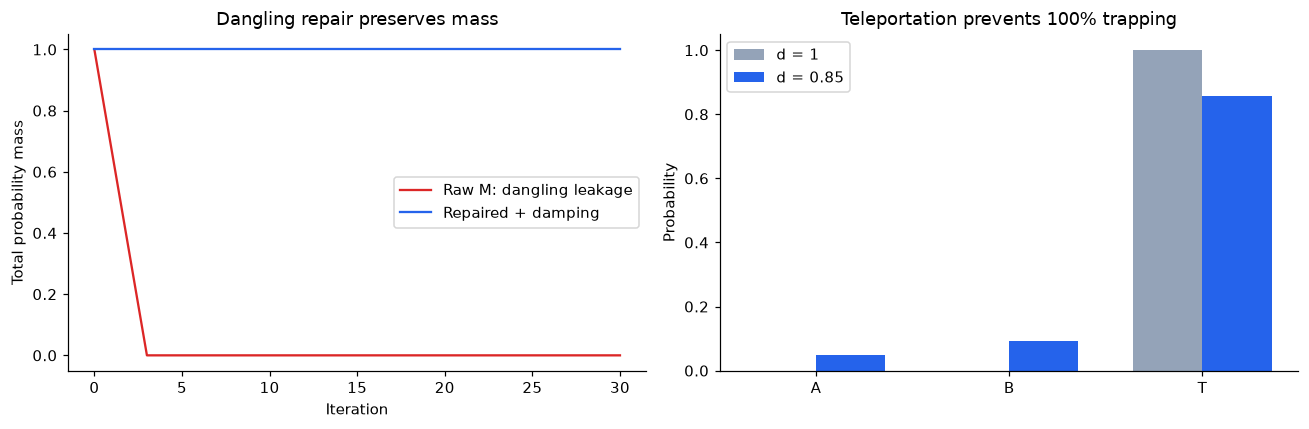

In [12]:
def pagerank_probability(adjacency,damping=0.85,iterations=30,repair_dangling=True):
    # adjacency[v,u] đếm cạnh v→u; chuyển vị để dùng vector cột.
    adjacency = np.asarray(adjacency,dtype=float)
    assert adjacency.ndim == 2 and adjacency.shape[0] == adjacency.shape[1]
    assert (adjacency >= 0).all() and 0 <= damping <= 1
    n = adjacency.shape[0]
    out_degree = adjacency.sum(axis=1)
    transition = np.divide(adjacency,out_degree[:,None],out=np.zeros_like(adjacency),
                           where=out_degree[:,None]>0).T
    if repair_dangling:
        transition[:,out_degree==0] = 1/n
    google = damping*transition + (1-damping)*np.ones((n,n))/n
    rank = np.ones(n)/n
    history = [rank.copy()]
    for _ in range(iterations):
        rank = google @ rank
        history.append(rank.copy())
    return np.asarray(history)

chain = np.array([[0,1,0],[0,0,1],[0,0,0]])
trap = chain.copy()
trap[2,2] = 1
raw_chain = pagerank_probability(chain,1,repair_dangling=False)
fixed_chain = pagerank_probability(chain,0.85)
trapped = pagerank_probability(trap,1)
escapable = pagerank_probability(trap,0.85)
assert np.allclose(raw_chain[:4].sum(axis=1),[1,2/3,1/3,0])
assert np.allclose(fixed_chain.sum(axis=1),1)
assert np.allclose(trapped[-1],[0,0,1])
assert np.allclose(escapable[-1],[0.05,0.0925,0.8575])
display(pd.DataFrame({'account':['A','B','T'],'d=1':trapped[-1],'d=0.85':escapable[-1]}))
fig,axes = plt.subplots(1,2,figsize=(12,4))
axes[0].plot(raw_chain.sum(axis=1),label='Raw M: dangling leakage',color='#dc2626')
axes[0].plot(fixed_chain.sum(axis=1),label='Repaired + damping',color='#2563eb')
axes[0].set(xlabel='Iteration',ylabel='Total probability mass',title='Dangling repair preserves mass')
axes[0].legend()
axes[1].bar(np.arange(3)-0.18,trapped[-1],width=0.36,label='d = 1',color='#94a3b8')
axes[1].bar(np.arange(3)+0.18,escapable[-1],width=0.36,label='d = 0.85',color='#2563eb')
axes[1].set(xticks=np.arange(3),xticklabels=['A','B','T'],ylabel='Probability',
            title='Teleportation prevents 100% trapping')
axes[1].legend()
plt.tight_layout()
plt.show()
checks_passed['PageRank: leakage, damping, mass and worked example'] = True


Nguồn lý thuyết đã dùng trong mục 3.3: Brin & Page (1998), *The Anatomy of a Large-Scale Hypertextual Web Search Engine*; Page et al. (1999), *The PageRank Citation Ranking*; Langville & Meyer (2004), *Deeper Inside PageRank*; Langville & Meyer (2006), *Google’s PageRank and Beyond*. Bản báo cáo: `docs/PartA_Theory.md`.


## 6 · Đối chiếu code và chốt lần chạy PaySim

Cell sau so AST các hàm hiển thị với source production của repo. Code thuật toán ở ngay trong notebook; hạ tầng Windows/Spark dùng module chung. Các bảng kết quả và kiểm tra ở trên được chạy lại từ input, không đọc output cũ để giả lập một lần chạy.


In [13]:
notebook_document = json.loads(NOTEBOOK_PATH.read_text(encoding='utf-8'))
visible_functions = {}
for cell in notebook_document['cells']:
    if cell['cell_type'] == 'code':
        for node in ast.parse(''.join(cell['source'])).body:
            if isinstance(node,ast.FunctionDef):
                visible_functions[node.name] = node
source_audit = []
for record in notebook_document['metadata']['graphguard_sources']:
    source = (REPO_ROOT/record['path']).read_text(encoding='utf-8')
    actual_functions = {n.name:n for n in ast.parse(source).body if isinstance(n,ast.FunctionDef)}
    for name in record['functions']:
        assert ast.dump(visible_functions[name],include_attributes=False) == ast.dump(
            actual_functions[name],include_attributes=False), f'Source drift: {record["path"]}:{name}'
    source_audit.append({'module':record['path'],'functions':', '.join(record['functions']),
                         'sha256':hashlib.sha256(source.encode('utf-8')).hexdigest(),'status':'MATCH'})
display(pd.DataFrame(source_audit))
checks_passed['All displayed production functions match repository AST'] = True


,module,functions,sha256,status
0,src/common/graph_utils.py,load_graph,b656fc4d7767fa1a3cc9bdb8e66101b0f6272daf01d586...,MATCH
1,src/motif/toy_cycle.py,"build_toy_graph, find_three_node_cycles, cycle...",44caa76842030eb834f9e854fd7f8b18cd5aabf2498f47...,MATCH
2,src/paysim/motif_finding.py,"find_relays, relay_rows",d6680cc1445accaba89d78af96ab82eb695148bbb52fb4...,MATCH


In [14]:
assert all(checks_passed.values())
finished_at = datetime.now(timezone.utc)
display(pd.DataFrame([{'check': name, 'status': 'PASS'} for name in checks_passed]))
display(pd.DataFrame([{
    'dataset': 'PaySim', 'scope': 'full',
    'started_utc': started_at.isoformat(), 'finished_utc': finished_at.isoformat(),
    'elapsed_seconds': round(time.perf_counter() - started_clock, 1),
    'review_scope': 'toy motif, Task 3 PaySim, PageRank 3.3',
    **runtime,
}]))
# Dừng Spark trước khi dọn checkpoint tạm ngoài repository.
spark.catalog.clearCache()
spark.stop()
runtime_temp.cleanup()
print('PASS — PaySim: toàn bộ notebook đã chạy, output và hình đã được lưu.')


,check,status
0,Windows Python 3.12 / JDK 17 / dependencies,PASS
1,Toy graph.find: 3 rotations / 1 cycle,PASS
2,PaySim: adversarial relay rules and three-node...,PASS
3,Task 3 PaySim full + exact delivered CSV,PASS
4,"PageRank: leakage, damping, mass and worked ex...",PASS
5,All displayed production functions match repos...,PASS


,dataset,scope,started_utc,finished_utc,elapsed_seconds,review_scope,system,python,spark,graphframes,java,master,driver_memory,session_timezone
0,PaySim,full,2026-10-18T13:43:03.702160+00:00,2026-10-18T13:45:47.561108+00:00,163.9,"toy motif, Task 3 PaySim, PageRank 3.3",Windows,3.12.10,3.5.1,0.12.2,17.0.20.1,local[4],6g,Asia/Saigon


PASS — PaySim: toàn bộ notebook đã chạy, output và hình đã được lưu.
